# 03 · Which tech companies announce layoffs? A first layoff-risk baseline

**Question.** Using only what a public company has reported in its filings, can we rank US tech companies by how likely they are to appear in the layoff tracker in the next two quarters, and what does the ranking depend on?

**Setup in one paragraph.** One row = one tech company (SEC SIC codes 357x, 366x, 367x, 737x) in one calendar quarter *t*. Features come from the filing quarter *t-1* (the report for *t* is not public yet). The label is 1 if the tracker lists a layoff at the company in quarter *t+1* or *t+2*. We train on rows up to 2022Q4 and test on 2023Q1 onward; the last two training quarters are dropped because their labels already look into the test period.

**Read this first.** The numbers quoted in the text are from the run of 2026-10-24. Re-running the notebook on the same data gives the same numbers (fixed seeds).

In [2]:
from pathlib import Path
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)      # the project's data paths are relative to the repo root
from analysis import company_models as cm
from analysis.company_panel import FEATURES
PROCESSED = ROOT / "data" / "processed"

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold"})
def save(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

panel = pd.read_csv(PROCESSED / "company_panel.csv", dtype={"sic": str, "sic2": str})
print(f"{len(panel):,} company-quarters | {panel['cik'].nunique()} companies | "
      f"{int(panel['y_next2q'].sum())} positive rows | base rate {panel['y_next2q'].mean():.2%}")

14,709 company-quarters | 866 companies | 447 positive rows | base rate 3.04%


## 1 · The panel: how often does a tech company show up in the tracker?

The tracker only starts in 2020 and the big wave came in 2022, so early quarters have almost no positives. That is why the time split matters: a model trained on 2020-2021 has seen very few layoffs.

,rows,positives,rate
year,,,
2020,2452,8,0.0033
2021,2543,5,0.0020
2022,2513,140,0.0557
2023,2415,105,0.0435
2024,2273,85,0.0374
2025,2096,81,0.0386
2026,417,23,0.0552


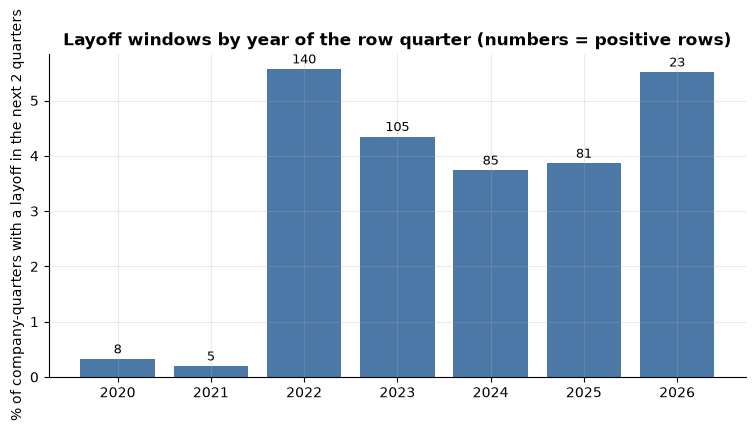

In [3]:
by_year = panel.assign(year=panel["quarter"].str[:4]).groupby("year")["y_next2q"].agg(rows="size", positives="sum", rate="mean")
display(by_year.round(4))

fig, ax = plt.subplots()
ax.bar(by_year.index, 100 * by_year["rate"], color="#4C78A8")
for x, (r, n) in zip(by_year.index, zip(by_year["rate"], by_year["positives"])):
    ax.text(x, 100 * r + 0.1, f"{int(n)}", ha="center", fontsize=9)
ax.set_ylabel("% of company-quarters with a layoff in the next 2 quarters")
ax.set_title("Layoff windows by year of the row quarter (numbers = positive rows)")
save(fig, "03_base_rate_by_year.png"); plt.show()

## 2 · Models and what beats what

Two deliberately small models: an L2 logistic regression and a shallow gradient-boosted tree. Everything estimated (clipping, medians, scaling, the models) uses training rows only. Confidence intervals resample **whole companies**, because rows of one company are strongly correlated.

We also refit both models **without company size** (log of total assets) to see whether anything else carries signal.

In [4]:
sc = cm.run_size_control(panel, embargo=True, n_boot=300)
res = sc["with_size"]
tr, te = res["train"], res["test"]
print(f"Train: {len(tr):,} rows, {int(tr['y_next2q'].sum())} positives ({tr['y_next2q'].mean():.2%})")
print(f"Test : {len(te):,} rows, {int(te['y_next2q'].sum())} positives ({te['y_next2q'].mean():.2%}), "
      f"{te.loc[te['y_next2q']==1, 'cik'].nunique()} companies with a positive")
overall = sc["overall"].set_index("model")
size_only = res["baselines"].set_index("feature").loc["log_assets"]
display(overall.round(4))
print(f"log assets alone (no model): PR-AUC {size_only['pr_auc']:.4f}, ROC-AUC {size_only['roc_auc']:.4f}")

Train: 6,206 rows, 55 positives (0.89%)
Test : 7,201 rows, 294 positives (4.08%), 90 companies with a positive


,pr_auc,ci_lo,ci_hi,lift,roc_auc,brier
model,,,,,,
constant (train base rate),0.0408,NaN,NaN,1.0000,0.5000,0.0402
logit_size,0.2838,0.1615,0.4359,6.9516,0.8457,0.0379
gb_size,0.1593,0.1106,0.2296,3.9011,0.8261,0.0386
logit_nosize,0.0762,0.0545,0.1070,1.8663,0.6940,0.0397
gb_nosize,0.0874,0.0640,0.1233,2.1400,0.7114,0.0397


log assets alone (no model): PR-AUC 0.3177, ROC-AUC 0.8201


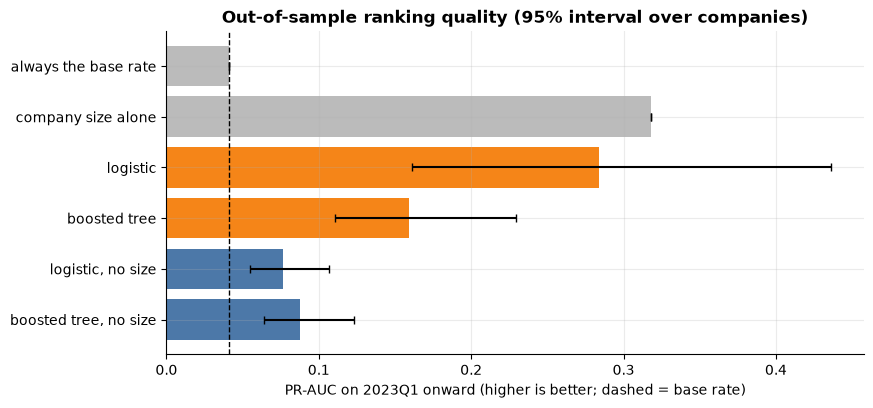

In [5]:
labels = ["always the base rate", "company size alone", "logistic", "boosted tree", "logistic, no size", "boosted tree, no size"]
vals = [overall.loc["constant (train base rate)", "pr_auc"], size_only["pr_auc"], overall.loc["logit_size", "pr_auc"],
        overall.loc["gb_size", "pr_auc"], overall.loc["logit_nosize", "pr_auc"], overall.loc["gb_nosize", "pr_auc"]]
keys = [None, None, "logit_size", "gb_size", "logit_nosize", "gb_nosize"]
err = [[0, 0] if k is None else [overall.loc[k, "pr_auc"] - overall.loc[k, "ci_lo"], overall.loc[k, "ci_hi"] - overall.loc[k, "pr_auc"]] for k in keys]
fig, ax = plt.subplots()
ax.barh(labels[::-1], vals[::-1], xerr=np.array(err).T[:, ::-1], color=["#BBBBBB", "#BBBBBB", "#F58518", "#F58518", "#4C78A8", "#4C78A8"][::-1], capsize=3)
ax.axvline(vals[0], color="k", ls="--", lw=1)
ax.set_xlabel("PR-AUC on 2023Q1 onward (higher is better; dashed = base rate)")
ax.set_title("Out-of-sample ranking quality (95% interval over companies)")
save(fig, "03_pr_auc.png"); plt.show()

## 3 · Is anything besides size doing the work? Compare inside size groups

Test rows are split into three size groups using the *training* terciles of log assets. Inside a group, size is roughly held constant. Groups with fewer than 15 positives are left blank.

model,gb_nosize,gb_size,logit_nosize,logit_size,rows,positives,base_rate
size_group,,,,,,,
1,NaN,NaN,NaN,NaN,2477,3,0.0012
2,1.77,1.71,1.47,1.67,2012,58,0.0288
3,1.47,2.21,1.43,3.93,2712,233,0.0859


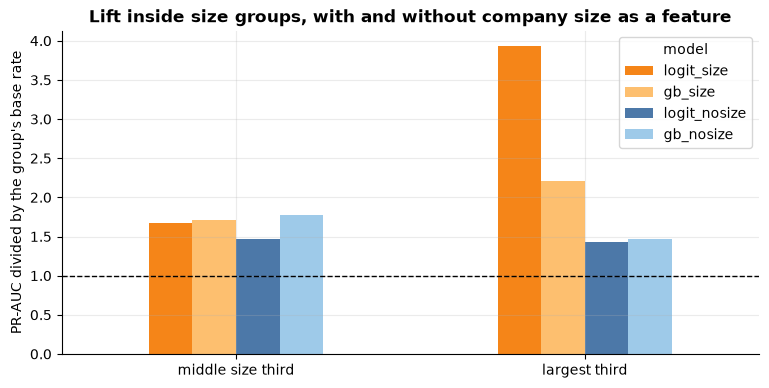

In [6]:
st = sc["stratified"]
display(st.pivot(index="size_group", columns="model", values="lift").round(2).assign(
    rows=st.groupby("size_group")["rows"].first(), positives=st.groupby("size_group")["positives"].first(),
    base_rate=st.groupby("size_group")["base_rate"].first().round(4)))

g = st[st["size_group"].isin([2, 3])].pivot(index="size_group", columns="model", values="lift")
fig, ax = plt.subplots()
g[["logit_size", "gb_size", "logit_nosize", "gb_nosize"]].plot.bar(ax=ax, rot=0, color=["#F58518", "#FDBF6F", "#4C78A8", "#9ecae9"])
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xticklabels(["middle size third", "largest third"]); ax.set_xlabel("")
ax.set_ylabel("PR-AUC divided by the group's base rate")
ax.set_title("Lift inside size groups, with and without company size as a feature")
save(fig, "03_lift_by_size_group.png"); plt.show()

## 4 · What do the models use?

In [7]:
print("Logistic regression (with size): effect per 1 standard deviation")
display(res["coefficients"].head(8).round(3))
print("Logistic regression WITHOUT size")
display(sc["without_size"]["coefficients"].head(8).round(3))
print("Single features on their own, direction chosen on training rows")
display(res["baselines"].round(4))

Logistic regression (with size): effect per 1 standard deviation


,feature,coef,odds_ratio
0,log_assets,1.787,5.973
1,sic_73,0.929,2.533
2,sic_36,-0.858,0.424
3,rnd_ratio_missing,-0.588,0.555
4,op_margin_missing,-0.504,0.604
5,cash_assets_missing,-0.481,0.618
6,rev_qoq,-0.439,0.645
7,rev_qoq_missing,0.385,1.470


Logistic regression WITHOUT size


,feature,coef,odds_ratio
0,sic_36,-1.036,0.355
1,cash_assets_missing,-0.972,0.379
2,sic_73,0.774,2.169
3,rnd_ratio_missing,-0.738,0.478
4,sga_ratio_missing,-0.606,0.545
5,op_margin,0.586,1.797
6,gross_margin_missing,0.479,1.615
7,op_margin_missing,-0.416,0.660


Single features on their own, direction chosen on training rows


,feature,direction,pr_auc,roc_auc
0,log_assets,higher = riskier,0.3177,0.8201
1,op_margin,higher = riskier,0.0685,0.6419
2,gross_margin,higher = riskier,0.0600,0.6417
3,net_loss,lower = riskier,0.0533,0.6053
4,rev_yoy,higher = riskier,0.0431,0.5509
5,rev_qoq,higher = riskier,0.0409,0.5346
6,rnd_ratio,higher = riskier,0.0402,0.5105
7,cash_assets,higher = riskier,0.0350,0.4634
8,sga_ratio,higher = riskier,0.0348,0.4448


## 5 · Calibration: the ranking transfers, the probabilities do not

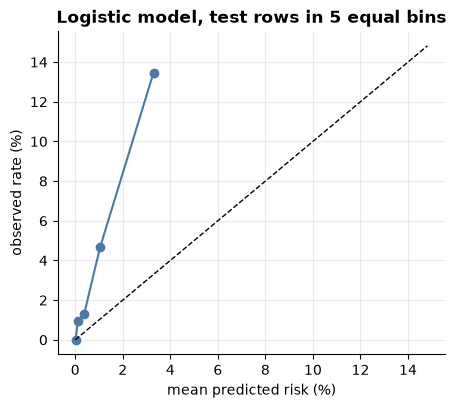

mean predicted 0.010 vs observed 0.041


,bin,n,predicted,observed
0,0,1441,0.0002,0.0000
1,1,1440,0.0011,0.0097
2,2,1440,0.0038,0.0132
3,3,1440,0.0104,0.0465
4,4,1440,0.0330,0.1347


In [8]:
cal = res["calibration"]["logit"]
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot(100 * cal["predicted"], 100 * cal["observed"], "o-", color="#4C78A8")
m = max(100 * cal["observed"].max(), 100 * cal["predicted"].max()) * 1.1
ax.plot([0, m], [0, m], "k--", lw=1)
ax.set_xlabel("mean predicted risk (%)"); ax.set_ylabel("observed rate (%)")
ax.set_title("Logistic model, test rows in 5 equal bins")
save(fig, "03_calibration.png"); plt.show()
print(f"mean predicted {res['scores']['logit'].mean():.3f} vs observed {te['y_next2q'].mean():.3f}")
display(cal.round(4))

## 6 · What we can and cannot say

**Results of the 2026-10-24 run** (training rows up to 2022Q2, test rows from 2023Q1: 7,201 company-quarters, 294 positives from 90 companies, base rate 4.1%).

1. **Ranking by filing data beats chance by a wide margin.** The logistic model reaches PR-AUC 0.28 (95% interval 0.16 to 0.44) against a base rate of 0.041, about 7 times better. The boosted tree is weaker (0.16) and less stable.
2. **Most of that is company size.** Total assets alone give PR-AUC 0.32, at least as good as either model. Without size the models fall to 0.076 (logistic) and 0.087 (tree), roughly twice the base rate (intervals 0.05 to 0.12).
3. **Inside size groups the picture is the same.** In the smallest third, the tracker has 3 positives in 2,477 rows, so no model can be evaluated there. In the middle third the models give about 1.5 to 1.8 times the base rate with or without size. In the largest third, the models that include size reach about 3.9 times the base rate (logistic), but without size only about 1.4 to 1.5 times. Size still matters *within* the largest third, so it is not just a threshold.
4. **Fundamentals add a weak signal at best.** Revenue growth, net loss, cash ratios and margins on their own are close to the base rate. The one feature that stands out without size is operating margin, and its sign is the opposite of distress: higher margin goes with higher tracker risk. A plausible reading is that the 2022-2025 layoffs were concentrated at large, profitable companies cutting costs, not at companies in financial trouble. This is an association in 90 companies, not an established cause.
5. **Industry matters.** Software and IT services (SIC 73) carry higher risk than hardware and semiconductors (SIC 36).
6. **Use the scores as a ranking, not as probabilities.** Predicted risk is about four times too low on average (0.010 vs 0.041) because training mostly covers the quiet period before the 2022 wave. The observed rate still rises from 0% in the lowest bin to 13.5% in the highest.

**Limits.**
- **The label is "appears in the layoff tracker", not "has layoffs".** The tracker records mostly notable layoffs, so large, well-known companies are more likely to be listed at all. The size effect may be partly a reporting effect. We have not tested this.
- **Few positives early.** There are only 55 positive rows in the training period, and almost all of them are from 2022. Models trained on so little are fragile, and results moved noticeably when the two embargoed quarters were added back (tree: 0.16 to 0.27).
- **Rows overlap.** Neighbouring quarters of one company share most of their label window, so the effective sample is closer to the 90 positive companies than to 294 positive rows.
- **Company matching is imperfect.** Tech companies with tracker layoffs that were not matched to an SEC filer are labelled "no layoff", which makes the models look slightly worse than they are.
- **Scope.** US-listed SEC filers in four SIC groups only; foreign filers (such as ASML) are missing; financials are calendar-aligned approximations of fiscal quarters; derived gross profit and SG&A are approximate for some companies.
- **No causal claim.** Nothing here shows what makes a company lay people off.

**Next steps worth considering:** separate "large, profitable cost-cutters" from "distressed small companies" instead of one model; add the macro conditions from the causes stream (interest rates, funding); and check how many tracker layoffs at known tech companies remain unmatched.